In [3]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import duecker_ET_model, simulate_dipole, jones_2009_model, MPIBackend

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology

# import pandas as pd
from scipy import signal
from scipy.optimize import curve_fit
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# plt.rcParams['svg.fonttype'] = 'none'
# plt.rcParams['pdf.fonttype'] = 'truetype'
mainpth = '/users/kduecker/hnn-tuning/'
pathfig = os.path.join(mainpth, 'new_model_HNN', 'figures', 'conn')
os.makedirs(pathfig, exist_ok=True)
pathpaper = os.path.join(mainpth, 'methods_paper')

import sys
sys.path.append(os.path.join(mainpth, 'utils'))
from general_plot_utils import assign_color, get_cmap_neurons

# colormap settings
from matplotlib import colormaps
import matplotlib.patches as mpatches

cmap = colormaps['Set2']

cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[3], 'L5_pyramidal': cmap.colors[4]}


# Hack a colormap

from scipy.interpolate import RectBivariateSpline
from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d
from hnn_core.viz import plot_laminar_csd

# Literature insights

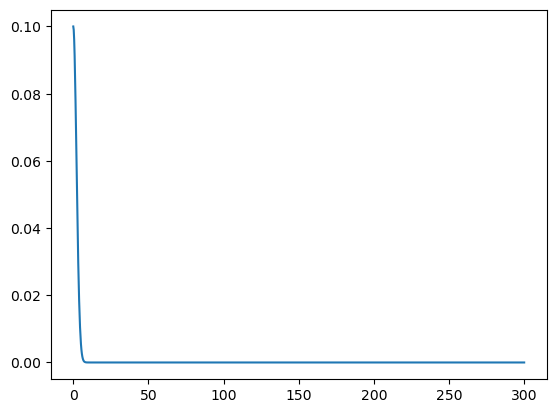

In [4]:
# Campagnola et al., 2022: Science, Fig. S5 suggests an all-to-all decay with gaussian = 130 um

def understand_space_constant(x, lamtha):
    """Explore effect of space constant on spike raster."""
    inplane_distance = 1  # example value
    A = 0.1
    return A*np.exp(-(x / (lamtha * inplane_distance)) ** 2)


x = np.linspace(0, 300, 1000)
plt.plot(x, understand_space_constant(x,3))

In [9]:
# according to Campagnola et al., 2022, Science, SI, p. 10
def gauss(x,sigma):
    A = 0.1
    gau = A*np.exp(-x**2/(2.*sigma**2))

    return gau

p0 = [10]
y = understand_space_constant(x, 183.75)
params, cov = curve_fit(gauss, x, y, p0=p0)
params

array([129.93087104])

In [10]:
inplane_distance = 30  # example value
lamtha = 183.75/inplane_distance
lamtha

6.125

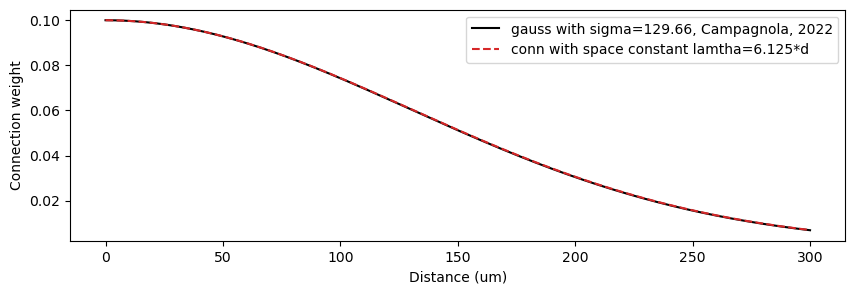

In [13]:
fig, ax = plt.subplots(figsize=(10,3))
ax.plot(x, 0.1*np.exp(-x**2/(2*129.66**2)), label='gauss with sigma=129.66, Campagnola, 2022', color='k')
ax.plot(x, y, linestyle='--', label='conn with space constant lamtha=6.125*d', color='C3')
ax.set_xlabel('Distance (um)')
ax.set_ylabel('Connection weight')
ax.legend()
fig.savefig(f'{pathfig}/connection_space_constant.png')
fig.savefig(f'{pathfig}/connection_space_constant.pdf')

In [ ]:
#lamtha = 183.75 for inplane_distance = 30

# Rheobase

In [2]:
## Not used in paper
def find_rheo(model='jones'):

    #fig, ax = plt.subplots(2,2, figsize=(12, 10))
    ax = ax.ravel()

    ampl = np.linspace(0.01, 1., 80)
    rheo = np.zeros((4,))

    for a in ampl: 
        if model == 'jones':
            net = jones_2009_model(mesh_shape=(1,1))
        else:
            net = duecker_ET_model(mesh_shape=(1,1))

        net.clear_connectivity()

        net.add_tonic_bias(cell_type='L2_basket', amplitude=a, t0=10., tstop=100.)
        net.add_tonic_bias(cell_type='L5_basket', amplitude=a, t0=10., tstop=100.)

        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100.)
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100.)

        dpl = simulate_dipole(net, tstop=100, n_trials=1, dt =0.01, record_vsec='soma')

        for i in range(4):

            if i == 2:
                rheo[i] == rheo[0]
            if rheo[i] == 0:
                if any((np.array(net.cell_response.spike_gids[0]) == i)):
                    rheo[i] = a
                    ax[i].plot(net.cell_response.times, net.cell_response.vsec[0][i]['soma'])
                    break

    return rheo


## Reported in paper
def find_basal_rheo(model='jones'):

    #fig, ax = plt.subplots(2,2, figsize=(12, 10))
    # ax = ax.ravel()

    ampl = np.linspace(0.01, 1., 80)
    rheo = np.zeros((4,))

    for a in ampl: 
        if model == 'jones':
            net = jones_2009_model(mesh_shape=(1,1))
        else:
            net = duecker_ET_model(mesh_shape=(1,1))

        net.clear_connectivity()

        net.add_tonic_bias(cell_type='L2_basket', amplitude=a, t0=10., tstop=100.)
        net.add_tonic_bias(cell_type='L5_basket', amplitude=a, t0=10., tstop=100.)

        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_2', bias_name='bias_1')
        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_3', bias_name='bias_2')
        net.add_tonic_bias(cell_type='L2_pyramidal', amplitude=a, t0=10., tstop=100., section='apical_oblique', bias_name='bias_3')
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_1', bias_name='bias_1')
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100., section='basal_2', bias_name='bias_2')
        net.add_tonic_bias(cell_type='L5_pyramidal', amplitude=a, t0=10., tstop=100., section='apical_oblique', bias_name='apical_oblique')

        dpl = simulate_dipole(net, tstop=100, n_trials=1, dt =0.01, record_vsec='soma')

        for i in range(4):

            if i == 2:
                rheo[i] == rheo[0]
            if rheo[i] == 0:
                if any((np.array(net.cell_response.spike_gids[0]) == i)):
                    rheo[i] = a
                    #ax[i].plot(net.cell_response.times, net.cell_response.vsec[0][i]['soma'])
                    break

    return rheo

In [3]:
# find rheobases for Jones cells

rheo_jones = find_basal_rheo(model='jones')
# find rheobases for new cells
rheo_ca = find_basal_rheo(model='ca')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.01 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applyi

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/dipole.py:76: UserWarning: No connections instantiated in network. Consider using net = jones_2009_model() or net = law_2021_model() to create a predefined network from published models.
  warnings.warn(


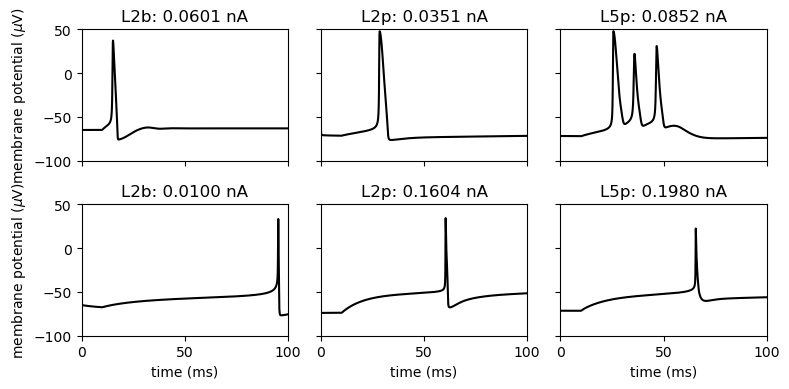

In [6]:
## rheobase plots
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']

jonnet = jones_2009_model(mesh_shape=(1,1))
jonnet.clear_connectivity()

canet = duecker_ET_model(mesh_shape=(1,1))
canet.clear_connectivity()

for i,c in enumerate(cell_types):
    if 'basket' in c:
        jonnet.add_tonic_bias(cell_type=c, amplitude=rheo_jones[i], t0=10., tstop=100., section='soma')
        canet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='soma')
    else:
        jonnet.add_tonic_bias(cell_type=c, amplitude=rheo_jones[i], t0=10., tstop=100., section='basal_1', bias_name='bias_1')
        canet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='basal_1', bias_name='bias_1')
        jonnet.add_tonic_bias(cell_type=c, amplitude=rheo_jones[i], t0=10., tstop=100., section='basal_2', bias_name='bias_2')
        canet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='basal_2', bias_name='bias_2')
        jonnet.add_tonic_bias(cell_type=c, amplitude=rheo_jones[i], t0=10., tstop=100., section='apical_oblique', bias_name='apical_oblique')
        canet.add_tonic_bias(cell_type=c, amplitude=rheo_ca[i], t0=10., tstop=100., section='apical_oblique', bias_name='apical_oblique')
# simulate dipole
dpl_jon = simulate_dipole(jonnet, tstop=100, n_trials=1, record_vsec='soma')
dpl_ca = simulate_dipole(canet, tstop=100, n_trials=1, record_vsec='soma')
fig, ax = plt.subplots(2, 3, figsize=(8, 4), sharex=True, sharey=True)

cell_types = ['L2b', 'L2p', 'L5b', 'L5p']
for i in range(3):
    if i == 2:
        c = i+1
    else:
        c = i
    ax[0,i].plot(jonnet.cell_response.times, jonnet.cell_response.vsec[0][c]['soma'], color='k')
    ax[1,i].plot(jonnet.cell_response.times, canet.cell_response.vsec[0][c]['soma'], color='k')
    ax[0,i].set_title(f'{cell_types[c]}: {rheo_jones[c]:.4f} nA')
    ax[1,i].set_title(f'{cell_types[c]}: {rheo_ca[c]:.4f} nA')
    ax[1,i].set_xlabel('time (ms)')
    ax[0,0].set_ylabel('membrane potential ($\mu$V)')
    ax[1,0].set_ylabel('membrane potential ($\mu$V)')
    ax[0,i].set_ylim(-100, 50)
    ax[1,i].set_ylim(-100, 50)
    ax[0,i].set_xlim(0, 100)
    ax[0,i].set_xticks([0, 50, 100])

fig.tight_layout()
fig.savefig(pathfig + 'rheobase_comparison.png')

## Jones model behavior

In [ ]:
net = jones_2009_model()

weights_ampa_p1 = {'L2_basket': 1, 'L2_pyramidal': 1.,
                   'L5_basket': 1, 'L5_pyramidal': 1.}
weights_nmda_p1 = {'L2_basket': 1, 'L2_pyramidal':1.,
                   'L5_basket': 1, 'L5_pyramidal': 1.}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}


# all NMDA weights are zero; pass None explicitly
net.add_evoked_drive(
    'evprox', mu=26.61, sigma=2.47, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


fig, ax = plt.subplots(2,1, figsize=(6, 6), height_ratios=[0.25, 1])

net.cell_response.plot_spikes_hist(ax=ax[0], spike_types=['evprox'], show=False)
net.cell_response.plot_spikes_raster(ax=ax[1], show=False)

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_spikes_prox.png'))

NameError: name 'jones_2009_model' is not defined

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applyi

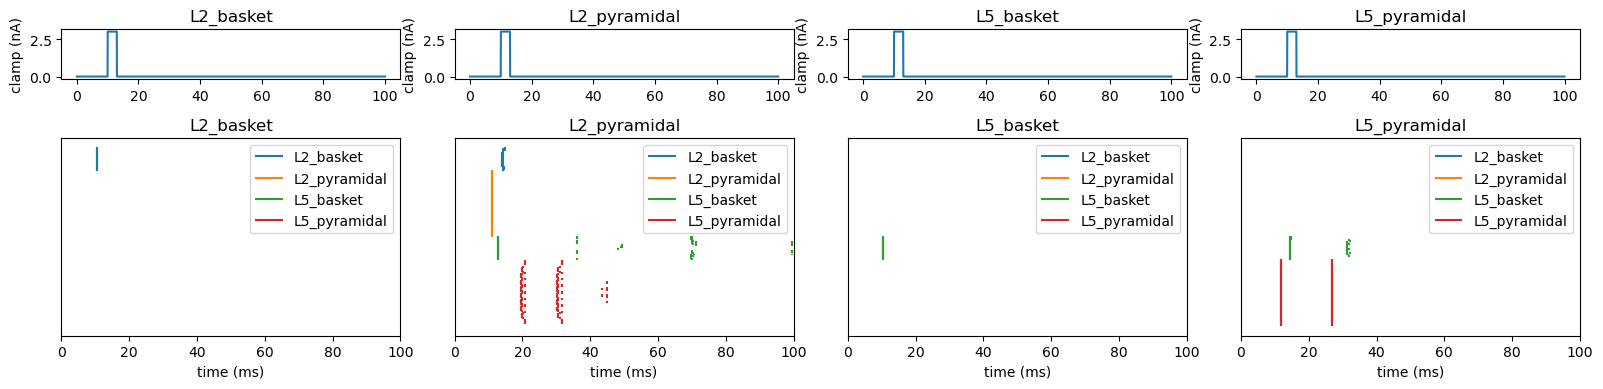

In [ ]:

fig, ax = plt.subplots(2,4, figsize=(16, 4), height_ratios=[0.25, 1])
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']

for i,c in enumerate(cell_types):
    # stimulate L2/3 pyramidal
    net = jones_2009_model()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2200,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    ampl = 3.
    t0 = 10

    net.add_tonic_bias(cell_type=c,section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

    dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

    # clamp signal for plotting
    timevec = net.cell_response.times

    clamp = np.zeros_like(timevec) 

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
            tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

            clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']
    
    


    ax[0,i].plot(timevec, clamp)
    ax[0,i].set_ylabel('clamp (nA)')
    ax[0,i].set_title(f'{cell_types[i]}')
    net.cell_response.plot_spikes_raster(ax=ax[1,i], show=False)
    ax[1,i].set_title(f'{cell_types[i]}')
    ax[1,i].set_xlabel('time (ms)')

    del net

for i in range(3):
    ax[1,i].set_ylim([ax[1,3].get_ylim()[0],ax[1,3].get_ylim()[1]])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_inter_layer.png'))

# the effect of L2/3 pyramidal stimulation on the L5 pyramidal cell is quite late (but removing connection gets rid of it so that's what's driving it)

# Connectivity

<>:53: SyntaxWarning: invalid escape sequence '\m'
<>:53: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_627199/3760554055.py:53: SyntaxWarning: invalid escape sequence '\m'
  cb.set_label('synaptic weight ($\mu S$)')
/tmp/ipykernel_627199/3760554055.py:49: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(xticklabels['L2_pyramidal'], rotation=45)


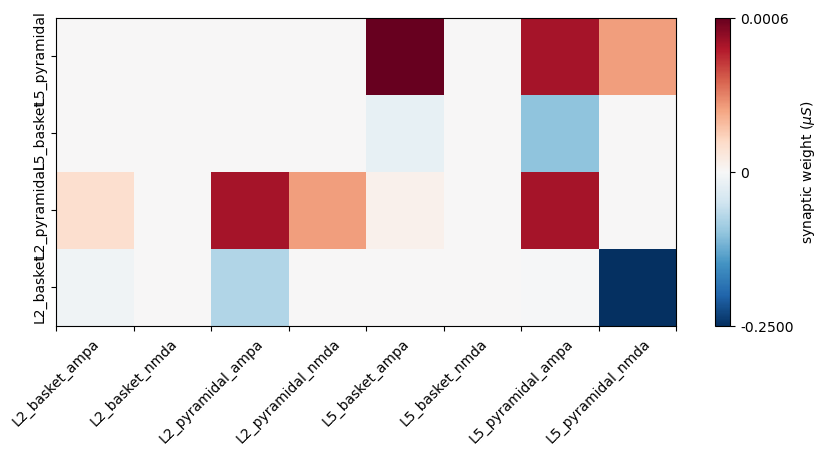

In [22]:
net = duecker_ET_model()

sources = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
E_receptors = ['ampa', 'nmda']
I_receptors = ['gabaa', 'gabab']

connectivity_data = dict()

for source in sources:
    connectivity_data[source] = dict()
    for conn in net.connectivity:
        if conn['src_type'] == source:
            t_type = conn['target_type']
            check_t = connectivity_data[source].get(t_type)

            if check_t is None:
                connectivity_data[source][t_type] = dict()       
            rec = conn['receptor']
            connectivity_data[source][t_type][rec] = conn['nc_dict']['A_weight']


conn_im = np.zeros((len(sources), len(sources), 2))

xticklabels = dict()
for s, source in enumerate(sources):
    xticks_source = []
    for t, target in enumerate(sources):
        
        check_t = connectivity_data[source].get(target)
        if 'basket' in source and check_t is not None:
            for i, rec in enumerate(I_receptors):
                if rec in connectivity_data[source][target]:
                    conn_im[s, t, i] = -connectivity_data[source][target][rec]
                xticks_source.append(f'{target}_{rec}')
        elif 'pyramidal' in source and check_t is not None:
            for i, rec in enumerate(E_receptors):
                if rec in connectivity_data[source][target]:
                    conn_im[s, t, i] = connectivity_data[source][target][rec]
                xticks_source.append(f'{target}_{rec}')
    xticklabels[source] = xticks_source

from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(10, 4))
norm = TwoSlopeNorm(vmin=np.min(conn_im+0.1), vmax=np.round(np.max(conn_im),4), vcenter=0)
im = ax.pcolormesh(conn_im.reshape(len(sources), len(sources)*2), cmap='RdBu_r', norm=norm)
ax.set_yticks(np.arange(.5, 4.5, 1))
ax.set_yticklabels(sources, rotation='vertical', va='center')
ax.set_xticklabels(xticklabels['L2_pyramidal'], rotation=45)
cb = plt.colorbar(im)
cb.set_ticks([np.min(conn_im+0.1), 0, np.round(np.max(conn_im),4)])
cb.set_ticklabels([f'{np.min(conn_im+0.1):.4f}', '0', f'{np.round(np.max(conn_im),4):.4f}'])
cb.set_label('synaptic weight ($\mu S$)')

fig.savefig(os.path.join(pathfig, 'conn_matrix.png'))
fig.savefig(os.path.join(pathfig, 'conn_matrix.pdf'))
fig.savefig(os.path.join(pathfig, 'conn_matrix.svg'))

# Strong proximal

In [ ]:
net = duecker_ET_model()
weights_ampa_p1 = {'L2_basket': 0.15, 'L2_pyramidal': 1.,
                   'L5_basket': 0.15, 'L5_pyramidal': 1.}
weights_nmda_p1 = {'L2_basket': 0.15, 'L2_pyramidal': 1.,
                   'L5_basket': 0.15, 'L5_pyramidal': 1.}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}


net.add_evoked_drive(
    'evprox', mu=26.61, sigma=3, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal',
    synaptic_delays=synaptic_delays_prox)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all', bsl_cor='calcium')


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading cu

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/parallel_backends.py:211: UserWarning: Received KeyboardInterrupt. Stopping simulation process...
  warn("Received KeyboardInterrupt. Stopping simulation process...")


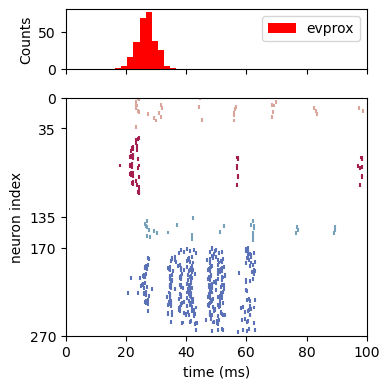

In [ ]:
fig, ax = plt.subplots(2,1, figsize=(4, 4), height_ratios=[0.25, 1], sharex=True)

net.cell_response.plot_spikes_hist(ax=ax[0], spike_types=['evprox'], show=False)

# spiking
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]
cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[2], 'L5_pyramidal': cmap.colors[3]}

colors = [assign_color(net, gid) for gid in gids]

ax[1].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
ax[1].set_ylabel('neuron index')
# ax[1].set_xlim([0, 175])
# ax[1].set_xticks(np.arange(0, 176, 25))

ax[1].set_xlabel('time (ms)')
ax[1].set_ylim([0, 270])
ax[1].set_yticks([0, 35, 135, 170, 270])
ax[1].invert_yaxis()
# ax2 = ax[1].twinx()
# ax2.plot(dpl[0].times, dpl[0].data['agg'], color='k')
fig.tight_layout()

fig.savefig(os.path.join(pathfig, 'net_rsp_prox_new_NMDA_new_lamtha.png'))

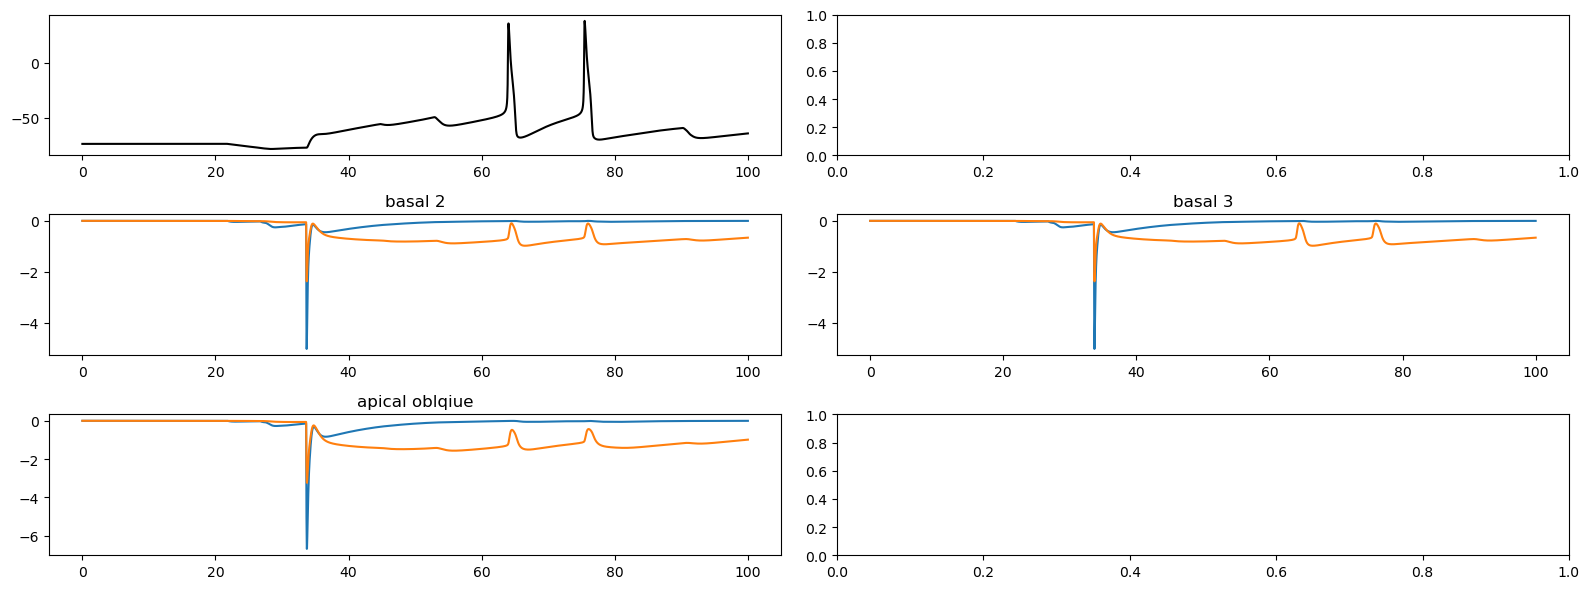

In [ ]:
values_l23, counts_l23 = np.unique(np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) > 35) & (np.array(net.cell_response.spike_gids[0]) <135)], return_counts=True)

gid_oi = values_l23[np.argmax(counts_l23)]

fig, ax = plt.subplots(3,2, figsize=(16, 6))
ax = ax.ravel()
ax[0].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'], color='k', linewidth=1.5)

ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_ampa'])
ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_nmda'])
ax[2].set_title('basal 2')
ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_ampa'])
ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_nmda'])
ax[3].set_title('basal 3')
ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_ampa'])
ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_nmda'])
ax[4].set_title('apical oblqiue')

fig.tight_layout()

In [ ]:
# values_l5, counts_l5 = np.unique(np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) > 170) & (np.array(net.cell_response.spike_gids[0]) <270)], return_counts=True)
# gid_oi = values_l5[np.argmax(counts_l5)]

# fig, ax = plt.subplots(3,2, figsize=(16, 6))
# ax = ax.ravel()
# ax[0].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'])
# ax[0].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['apical_tuft'])

# ax[1].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_1']['basal_1_ampa'])
# ax[1].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_1']['basal_1_nmda'])
# ax[1].set_title('basal 1')
# ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_ampa'])
# ax[2].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_2']['basal_2_nmda'])
# ax[2].set_title('basal 2')
# ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_ampa'])
# ax[3].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['basal_3']['basal_3_nmda'])
# ax[3].set_title('basal 3')
# ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_ampa'])
# ax[4].plot(net.cell_response.times,net.cell_response.isec[0][gid_oi]['apical_oblique']['apical_oblique_nmda'])
# ax[4].set_title('apical oblqiue')

# fig.tight_layout()

In [ ]:
# fig, ax = plt.subplots(2,5, figsize=(20, 5))

# sel_random = np.random.choice(len(few_spikes), 5)
# for i,gid_oi in enumerate(few_spikes[sel_random]):
#     ax[0,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'])
#     ax[0,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['apical_tuft'])

# sel_random = np.random.choice(len(many_spikes), 5)
# for i,gid_oi in enumerate(many_spikes[sel_random]):
#     ax[1,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['soma'])
#     ax[1,i].plot(net.cell_response.times,net.cell_response.vsec[0][gid_oi]['apical_tuft'])

# ax[0,0].set_ylabel('membrane potential (mV)')
# ax[1,0].set_ylabel('membrane potential (mV)')
# ax[1,0].set_xlabel('time (ms)')

# fig.savefig(os.path.join(pathfig, 'few_vs_many_aps_calcium_spike.png'))

In [ ]:
from hnn_core.cell import _get_gaussian_connection

# this is from the plotting function
exc_cells = ['L2_pyramidal', 'L5_pyramidal']
inh_cells = ['L2_basket', 'L5_basket']

conn_strength_exc = dict()
conn_strength_inh = dict()


for conn in net.connectivity:
    nc_dict = conn['nc_dict']
    src_type = conn['src_type']
    target_type = conn['target_type']
    src_type_pos = net.pos_dict[src_type]
    target_type_pos = net.pos_dict[target_type]

    src_range = np.array(net.gid_ranges[conn['src_type']])
    target_range = np.array(net.gid_ranges[conn['target_type']])
    connectivity_matrix = np.zeros((len(src_range), len(target_range)))

    for src_gid, target_src_pair in conn['gid_pairs'].items():
        src_idx = np.where(src_range == src_gid)[0][0]
        target_indeces = np.where(np.isin(target_range, target_src_pair))[0]
        for target_idx in target_indeces:
            src_pos = src_type_pos[src_idx]
            target_pos = target_type_pos[target_idx]

            weight, _ = _get_gaussian_connection(
                src_pos, target_pos, nc_dict,
                inplane_distance=net._inplane_distance)

            connectivity_matrix[src_idx, target_idx] = weight

    if conn['src_type'] in exc_cells:
        conn_strength_exc[conn['src_type'] + '-' + conn['target_type']] = connectivity_matrix.sum()
    elif conn['src_type'] in inh_cells:
        conn_strength_inh[conn['src_type'] + '-' + conn['target_type']] = connectivity_matrix.sum()




Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Applying Jones baseline correction


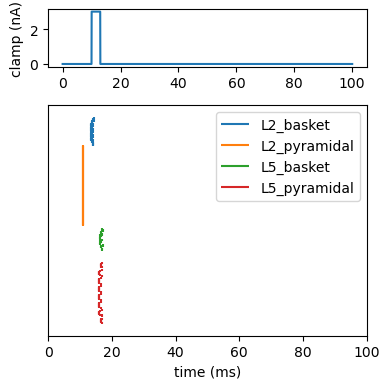

In [ ]:
fig, ax = plt.subplots(2,1, figsize=(4, 4), height_ratios=[0.25, 1])

# stimulate L2/3 pyramidal
net = duecker_ET_model()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 10

net.add_tonic_bias(cell_type='L2_pyramidal',section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1)

# clamp signal for plotting
timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

    ax[0].plot(timevec, clamp)
    ax[0].set_ylabel('clamp (nA)')
    net.cell_response.plot_spikes_raster(ax=ax[1], show=False)
    ax[1].set_xlabel('time (ms)')

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'new_l2.png'))

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

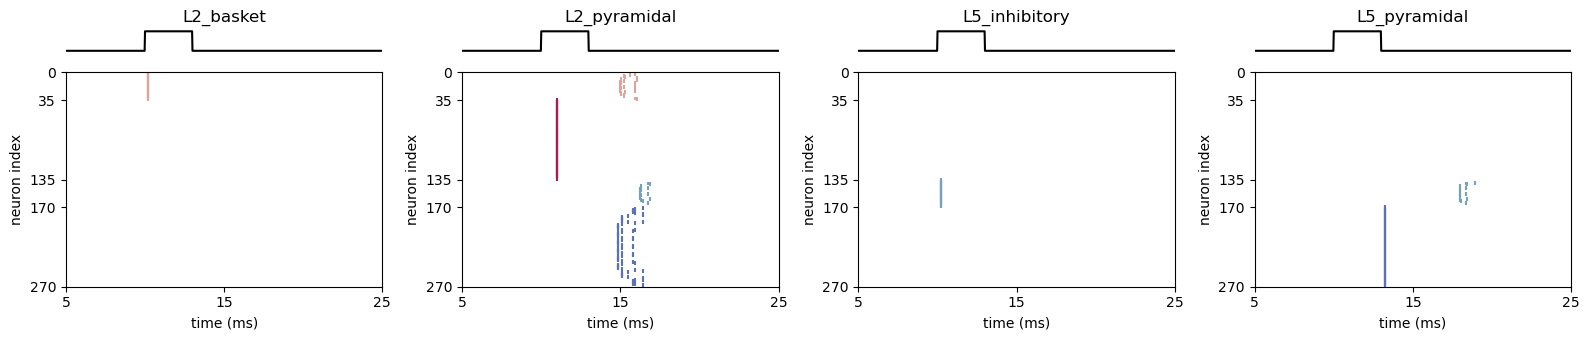

In [ ]:
fig, ax = plt.subplots(2,4, figsize=(16, 3.5), height_ratios=[0.1, 1], sharex=True)

cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
for i,c in enumerate(cell_types):
    # stimulate L2/3 pyramidal
    net = duecker_ET_model()

    net.set_cell_positions(inplane_distance=30.)

    depths = list(list(range(-100,2200,200)))
    electrode_pos = [(135, 135, dep) for dep in depths]

    net.add_electrode_array('probe1', electrode_pos)

    ampl = 3.
    t0 = 10

    net.add_tonic_bias(cell_type=c,section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

    with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
        dpl = simulate_dipole(net, tstop=30, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

    # clamp signal for plotting
    timevec = net.cell_response.times

    clamp = np.zeros_like(timevec) 

    for bias in net.external_biases:
        for cell_type in net.external_biases[bias]:
            t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
            tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

            clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']
    
    


    ax[0,i].plot(timevec, clamp, color='k', linewidth=1.5)
    ax[0,i].set_ylabel('clamp (nA)')
    ax[0,i].set_title(f'{cell_types[i]}')

    I = np.array(net.cell_response.spike_gids[0]) <270
    gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
    times = np.array(net.cell_response.spike_times).reshape(-1,)[I]
    cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
    cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
                'L5_basket': cmap.colors[2], 'L5_pyramidal': cmap.colors[3]}

    colors = [assign_color(net, gid) for gid in gids]

    ax[1,i].scatter(times, gids, s=8, alpha=1., c=colors, marker='|')
    ax[1,i].set_ylabel('neuron index')
    ax[1,i].set_xlim([5, 25])
    ax[0,i].set_xlim([5, 25])
    ax[0,i].set_axis_off()
    ax[1,i].set_xticks(np.arange(5, 26, 10))
    ax[1,i].set_xlabel('time (ms)')
    ax[1,i].set_ylim([0, 270])
    ax[1,i].set_yticks([0, 35, 135, 170, 270])
    ax[1,i].invert_yaxis()

for i in range(3):
    ax[1,i].set_ylim([ax[1,3].get_ylim()[0],ax[1,3].get_ylim()[1]])
fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'new_model_inter_layer_exp.png'))
fig.savefig(os.path.join(pathfig, 'new_model_inter_layer_exp.pdf'))